In [6]:
!pip -q install pandas openpyxl prophet scikit-learn requests

import os
import zipfile
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
zip_path = "/content/online_retail.zip"
extract_path = "/content/online_retail"

response = requests.get(url, timeout=120)
response.raise_for_status()

with open(zip_path, "wb") as f:
    f.write(response.content)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

# Find the Excel file inside the extracted folder
xlsx_files = []
for root, dirs, filenames in os.walk(extract_path):
    for filename in filenames:
        if filename.lower().endswith(".xlsx"):
            xlsx_files.append(os.path.join(root, filename))

if not xlsx_files:
    raise FileNotFoundError("No Excel file found in the downloaded ZIP.")

df = pd.read_excel(xlsx_files[0])

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset loaded successfully!
Shape: (541909, 8)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [7]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDate range:")
print(df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

display(df.describe(include="all").T)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate rows: 5268

Date range:
2010-12-01 08:26:00 to 2011-12-09 12:50:00


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"], errors="coerce"
)

df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")

df = df.drop_duplicates()
df = df.dropna(subset=["InvoiceDate", "Quantity", "UnitPrice"])

# Remove cancelled invoices (invoice numbers beginning with C)
cancelled = df["InvoiceNo"].astype(str).str.upper().str.startswith("C")
df = df[~cancelled].copy()

# Keep valid sales transactions
df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

# Calculate transaction-line revenue in GBP
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

print("Cleaned dataset shape:", df.shape)
print("Remaining missing values:")
print(df[["InvoiceDate", "Quantity", "UnitPrice", "Revenue"]].isnull().sum())

display(df.head())

Cleaned dataset shape: (524878, 9)
Remaining missing values:
InvoiceDate    0
Quantity       0
UnitPrice      0
Revenue        0
dtype: int64


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [9]:
daily_sales = (
    df.set_index("InvoiceDate")["Revenue"]
    .resample("D")
    .sum()
    .rename("Sales")
    .to_frame()
)

# Keep the complete calendar timeline
daily_sales = daily_sales.asfreq("D", fill_value=0)

daily_sales.index.name = "Date"

print("Daily sales dataset:", daily_sales.shape)
display(daily_sales.head(10))

Daily sales dataset: (374, 1)


,Sales
Date,
2010-12-01,58776.79
2010-12-02,47629.42
2010-12-03,46898.63
2010-12-04,0.00
2010-12-05,31364.63
2010-12-06,54624.15
2010-12-07,99553.85
2010-12-08,45235.36
2010-12-09,53548.19


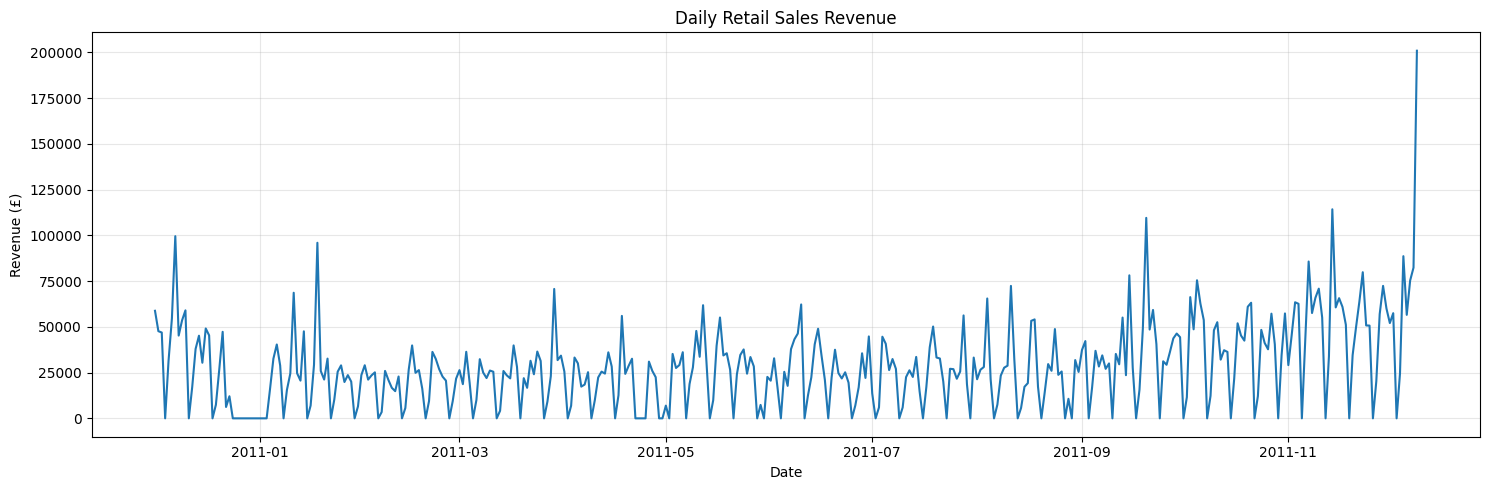

In [10]:
plt.figure(figsize=(15, 5))

plt.plot(daily_sales.index, daily_sales["Sales"])

plt.title("Daily Retail Sales Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue (£)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

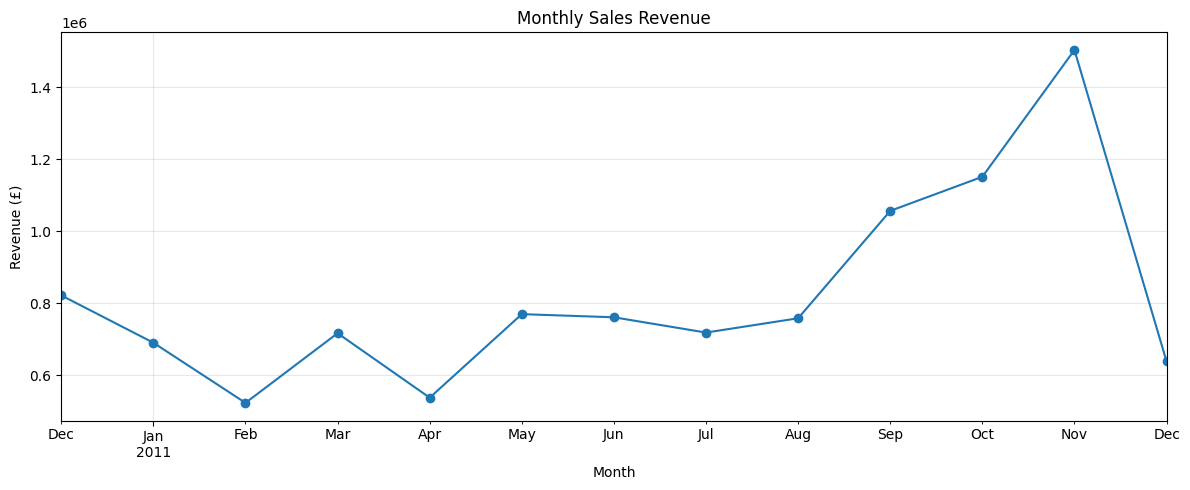

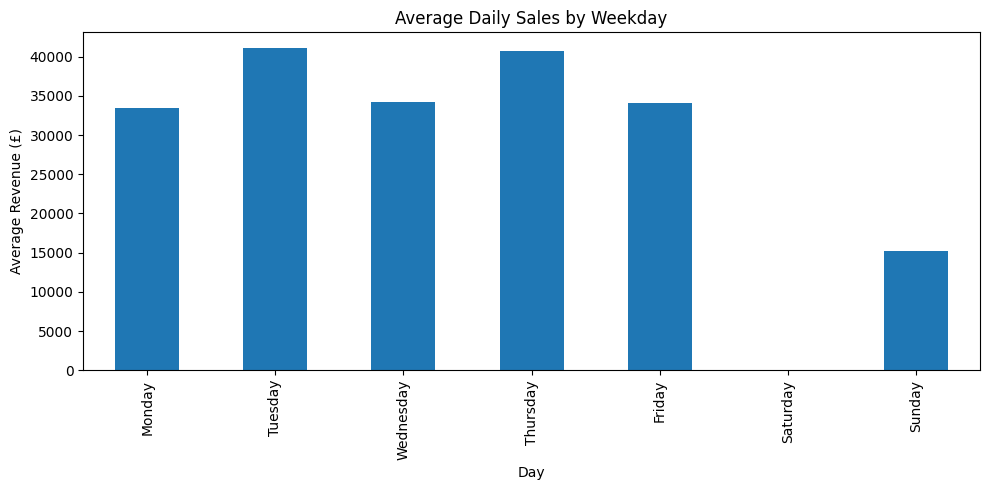

,Monthly_Revenue
Date,
2010-12-31,821452.730
2011-01-31,689811.610
2011-02-28,522545.560
2011-03-31,716215.260
2011-04-30,536968.491
2011-05-31,769296.610
2011-06-30,760547.010
2011-07-31,718076.121
2011-08-31,757841.380


In [11]:
# Monthly revenue
monthly_sales = daily_sales["Sales"].resample("ME").sum()

plt.figure(figsize=(12, 5))
monthly_sales.plot(marker="o")
plt.title("Monthly Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Average sales by weekday
weekday_sales = daily_sales.groupby(
    daily_sales.index.day_name()
)["Sales"].mean()

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_sales = weekday_sales.reindex(weekday_order)

plt.figure(figsize=(10, 5))
weekday_sales.plot(kind="bar")
plt.title("Average Daily Sales by Weekday")
plt.xlabel("Day")
plt.ylabel("Average Revenue (£)")
plt.tight_layout()
plt.show()

display(monthly_sales.to_frame("Monthly_Revenue"))

In [12]:
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error

model_df = daily_sales.reset_index()
model_df.columns = ["ds", "y"]

test_days = 30

train_df = model_df.iloc[:-test_days].copy()
test_df = model_df.iloc[-test_days:].copy()

print("Training period:", train_df["ds"].min(), "to", train_df["ds"].max())
print("Testing period:", test_df["ds"].min(), "to", test_df["ds"].max())
print("Training records:", len(train_df))
print("Testing records:", len(test_df))

Training period: 2010-12-01 00:00:00 to 2011-11-09 00:00:00
Testing period: 2011-11-10 00:00:00 to 2011-12-09 00:00:00
Training records: 344
Testing records: 30


In [13]:
model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode="additive",
    interval_width=0.95
)

model.fit(train_df)

# Predict only the dates in the test period
future = test_df[["ds"]].copy()
forecast = model.predict(future)

results = test_df[["ds", "y"]].copy()
results["Predicted_Sales"] = forecast["yhat"].values
results["Lower_Bound"] = forecast["yhat_lower"].values
results["Upper_Bound"] = forecast["yhat_upper"].values

display(results.head(10).round(2))

,ds,y,Predicted_Sales,Lower_Bound,Upper_Bound
344,2011-11-10,70868.00,61984.07,39063.82,85071.88
345,2011-11-11,55107.87,52851.39,29598.20,76069.34
346,2011-11-12,0.00,24068.34,2309.24,46720.39
347,2011-11-13,33878.15,38410.82,14142.85,62776.88
348,2011-11-14,114237.40,54347.53,30357.61,78400.93
349,2011-11-15,60613.80,63816.24,39876.73,85967.84
350,2011-11-16,65672.53,55529.94,34596.57,78346.53
351,2011-11-17,60901.32,63260.74,39923.55,87034.27
352,2011-11-18,51130.39,54060.10,31502.75,75063.07
353,2011-11-19,0.00,25241.20,2214.68,50151.48


In [14]:
actual = results["y"].to_numpy()
predicted = results["Predicted_Sales"].to_numpy()

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

# MAPE is unstable for days with zero sales
nonzero = actual != 0

if nonzero.any():
    mape = np.mean(
        np.abs(
            (actual[nonzero] - predicted[nonzero]) / actual[nonzero]
        )
    ) * 100
else:
    mape = np.nan

print("MODEL EVALUATION")
print("----------------")
print(f"MAE:  £{mae:,.2f}")
print(f"RMSE: £{rmse:,.2f}")
print(f"MAPE on nonzero-sales days: {mape:.2f}%")

MODEL EVALUATION
----------------
MAE:  £18,624.06
RMSE: £34,523.96
MAPE on nonzero-sales days: 22.83%


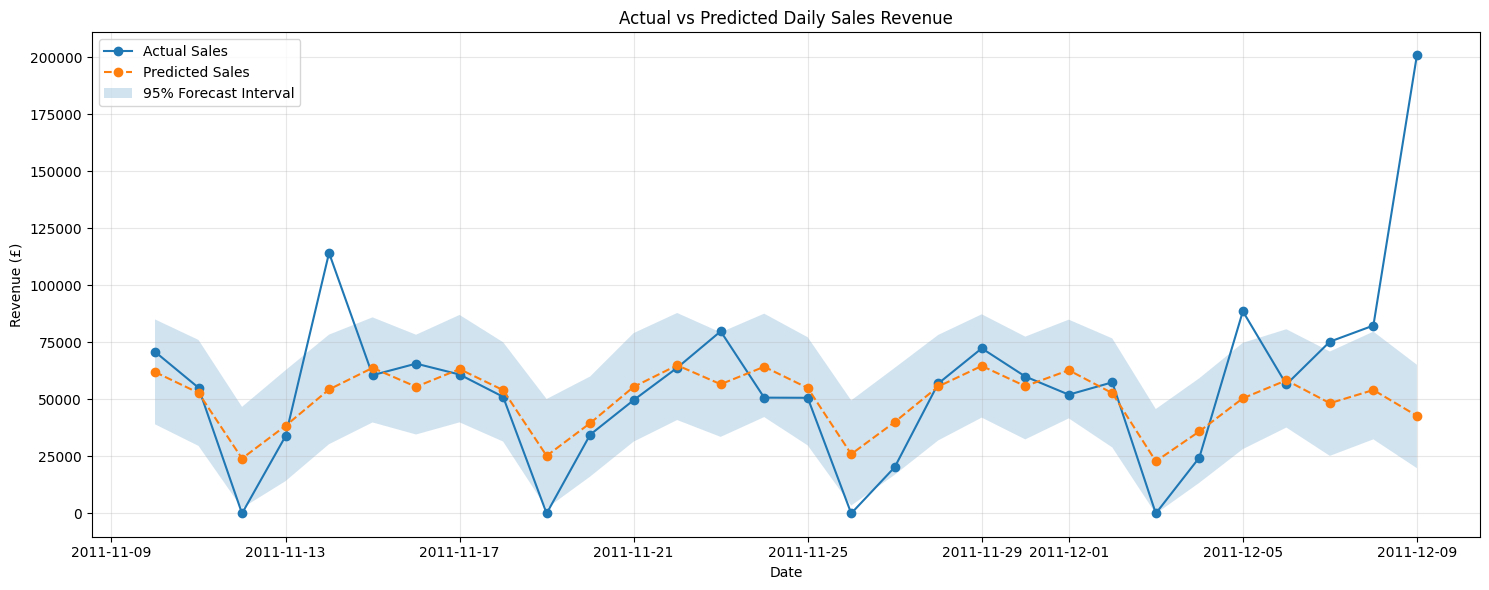

In [15]:
plt.figure(figsize=(15, 6))

plt.plot(
    results["ds"], results["y"],
    marker="o", label="Actual Sales"
)

plt.plot(
    results["ds"], results["Predicted_Sales"],
    linestyle="--", marker="o", label="Predicted Sales"
)

plt.fill_between(
    results["ds"],
    results["Lower_Bound"],
    results["Upper_Bound"],
    alpha=0.2,
    label="95% Forecast Interval"
)

plt.title("Actual vs Predicted Daily Sales Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue (£)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()